# Hidden Value: Phase 3 - Exploration

**Goal of this notebook:** look at the drive table before calculating anything. No Drive Quality Score, no weights, no rankings, no case studies. Just understand the shape of the data so Phase 4+ is built on reality instead of assumptions.

Grounded in **Design Doc v1.0**. Two rules from the doc govern everything here:
- We look before we calculate. Distributions first, conclusions never (yet).
- We respect the sample. Early in 2026 there are almost no games, so this notebook is about whether the *pipeline output behaves sensibly*, not about ranking anyone. The 40-drive gate (Sec 15) is nowhere close yet, and that is expected.

> Run this after your Phase 2 export exists. It reads the CSV; it does not pull new data.

## 1. Setup and load

In [11]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# Point this at your Phase 2 output.
CSV = r"C:\Users\brade\OneDrive - Worcester Polytechnic Institute (wpi.edu)\Desktop\Football\hidden_value_2026_drives.csv"
drives = pd.read_csv(CSV)

print("drives:", len(drives))
print("games:", drives["game_id"].nunique(),
      "| weeks:", sorted(drives["week"].unique().tolist()),
      "| teams:", drives["posteam"].nunique())
drives.head()

drives: 1357
games: 65 | weeks: [1, 2, 3, 4, 5] | teams: 32


,drive_id,game_id,season,week,posteam,defteam,fixed_drive,drive_result,drive_start_yard_line,qualifying_plays,pass_plays,rush_plays,success_plays,epa_sum,explosive_plays,third_down_conversions,negative_plays,sacks,turnovers,gt_qual_plays,third_down_attempts,start_yardline_100,deepest_yardline_100,td_drive,fg_drive,offensive_points,net_points,clock_expiration,reached_40,reached_20,garbage_time
0,2026_01_ARI_LAC_1,2026_01_ARI_LAC,2026,1,ARI,LAC,1.0,Touchdown,ARI 30,11,4,7,7,5.700554,2,2.0,0,0,0,0,2.0,70.0,0.0,1,0,7,7,0,1,1,0
1,2026_01_ARI_LAC_2,2026_01_ARI_LAC,2026,1,LAC,ARI,2.0,Touchdown,LAC 23,8,3,5,4,5.313758,3,1.0,0,0,0,0,1.0,77.0,0.0,1,0,7,7,0,1,1,0
2,2026_01_ARI_LAC_3,2026_01_ARI_LAC,2026,1,ARI,LAC,3.0,Missed field goal,ARI 30,7,5,2,3,1.032609,1,0.0,1,0,0,0,1.0,70.0,36.0,0,0,0,0,0,1,0,0
3,2026_01_ARI_LAC_4,2026_01_ARI_LAC,2026,1,LAC,ARI,4.0,Turnover,LAC 44,4,2,2,2,-4.188022,1,0.0,1,0,1,0,0.0,56.0,30.0,0,0,0,0,0,1,0,0
4,2026_01_ARI_LAC_5,2026_01_ARI_LAC,2026,1,ARI,LAC,5.0,Field goal,ARI 34,11,6,5,6,2.966778,1,2.0,2,0,0,0,3.0,66.0,9.0,0,1,3,3,0,1,1,0


## 2. Sample-size reality check\n\nBefore any distribution, know how little (or much) data we have. This decides what we are allowed to say.

In [13]:
print("=== SAMPLE SIZE (Design Doc Sec 15: 40 drives per team before rankings) ===\n")

per_team = (drives[drives["garbage_time"]==0]
            .groupby("posteam").size().sort_values(ascending=False))
print("non-garbage drives per team:")
print(per_team.to_string())

n_ready = (per_team >= 40).sum()
print(f"\nteams at/over the 40-drive gate: {n_ready} of {drives['posteam'].nunique()}")
if n_ready == 0:
    print(">> Too early for team rankings. This notebook validates pipeline behavior only.")

=== SAMPLE SIZE (Design Doc Sec 15: 40 drives per team before rankings) ===

non-garbage drives per team:
posteam
TB     48
WAS    42
PIT    41
HOU    41
MIN    40
DAL    40
SEA    39
GB     38
LAC    38
IND    38
PHI    37
ARI    37
BUF    37
NO     36
KC     36
LA     36
ATL    35
LV     35
CHI    35
NYG    34
CAR    34
CLE    33
NE     33
DEN    33
BAL    33
DET    32
NYJ    31
CIN    29
JAX    28
TEN    28
SF     27
MIA    26

teams at/over the 40-drive gate: 6 of 32


## 3. How drives end\n\nThe distribution of `drive_result` is the fastest sanity check on the whole dataset. The proportions should look like football.

                   drives   pct
drive_result                   
Punt                  493  36.3
Touchdown             325  23.9
Field goal            223  16.4
Turnover              141  10.4
Turnover on downs      72   5.3
End of half            56   4.1
Missed field goal      37   2.7
Opp touchdown           9   0.7
Safety                  1   0.1


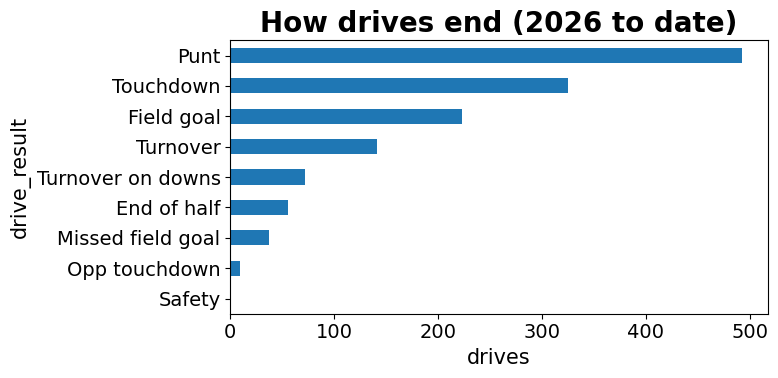


share of drives that scored (TD or FG): 40.4%
league-typical is very roughly 35-42% once samples are large.


In [14]:
vc = drives["drive_result"].value_counts(dropna=False)
pct = (vc / len(drives) * 100).round(1)
summary = pd.DataFrame({"drives": vc, "pct": pct})
print(summary.to_string())

plt.figure(figsize=(8,4))
vc.sort_values().plot(kind="barh")
plt.title("How drives end (2026 to date)")
plt.xlabel("drives")
plt.tight_layout()
plt.show()

# quick reasonableness note
score_rate = drives["offensive_points"].gt(0).mean()*100
print(f"\nshare of drives that scored (TD or FG): {score_rate:.1f}%")
print("league-typical is very roughly 35-42% once samples are large.")

## 4. The outcome variable: points per drive\n\nThis is what everything will eventually be explained against (Sec 10). Look at it before modeling it.

offensive_points distribution:
offensive_points
0    809
3    223
7    325

mean points/drive: 2.169
scoring drives: 40.4%  |  TD drives: 23.9%

net vs offensive points (net penalizes giveaways, Sec 10):
mean offensive: 2.169  |  mean net: 2.122


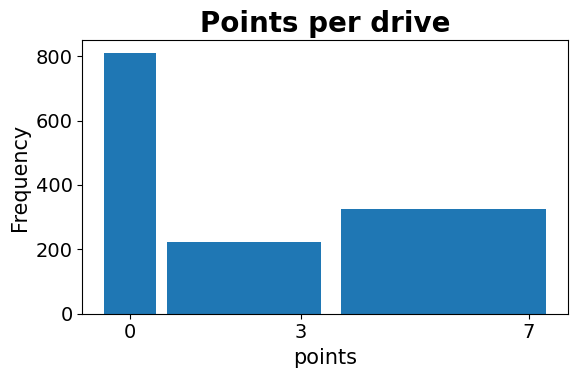

In [15]:
pts = drives["offensive_points"]
print("offensive_points distribution:")
print(pts.value_counts().sort_index().to_string())
print(f"\nmean points/drive: {pts.mean():.3f}")
print(f"scoring drives: {pts.gt(0).mean()*100:.1f}%  |  TD drives: {drives['td_drive'].mean()*100:.1f}%")

print("\nnet vs offensive points (net penalizes giveaways, Sec 10):")
print(f"mean offensive: {drives['offensive_points'].mean():.3f}  |  mean net: {drives['net_points'].mean():.3f}")

plt.figure(figsize=(6,4))
pts.plot(kind="hist", bins=[-0.5,0.5,3.5,7.5], rwidth=0.9)
plt.xticks([0,3,7]); plt.title("Points per drive"); plt.xlabel("points")
plt.tight_layout(); plt.show()

## 5. Starting field position\n\nThe inherited condition we must separate from what the offense did (Sec 8). Confirm it looks like real starting spots, centered near the mid-70s (own 25ish).

start_yardline_100 (100 = own goal line, lower = closer to scoring)
mean: 69.7  median: 71.0  min: 1  max: 99
(a typical own-25 start = 75; expect most mass in the 70s-80s)


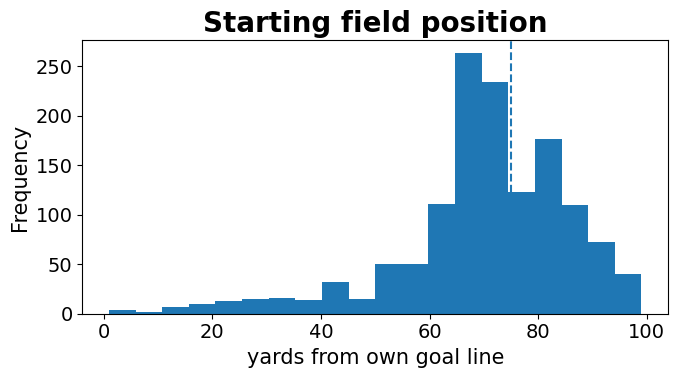

In [16]:
fp = drives["start_yardline_100"].dropna()
print(f"start_yardline_100 (100 = own goal line, lower = closer to scoring)")
print(f"mean: {fp.mean():.1f}  median: {fp.median():.1f}  min: {fp.min():.0f}  max: {fp.max():.0f}")
print("(a typical own-25 start = 75; expect most mass in the 70s-80s)")

plt.figure(figsize=(7,4))
fp.plot(kind="hist", bins=20)
plt.axvline(75, ls="--")
plt.title("Starting field position"); plt.xlabel("yards from own goal line")
plt.tight_layout(); plt.show()

## 6. The three dimensions, unweighted\n\nLook at efficiency, explosiveness, and finishing as raw drive-level numbers. We are NOT combining them yet. We just want to see how they spread and whether any column looks broken.

success_rate    mean 0.378 | median 0.375 | min 0.000 | max 1.000
epa_per_play    mean -0.191 | median -0.153 | min -7.130 | max 5.212
explosive_rate  mean 0.120 | median 0.000 | min 0.000 | max 1.000


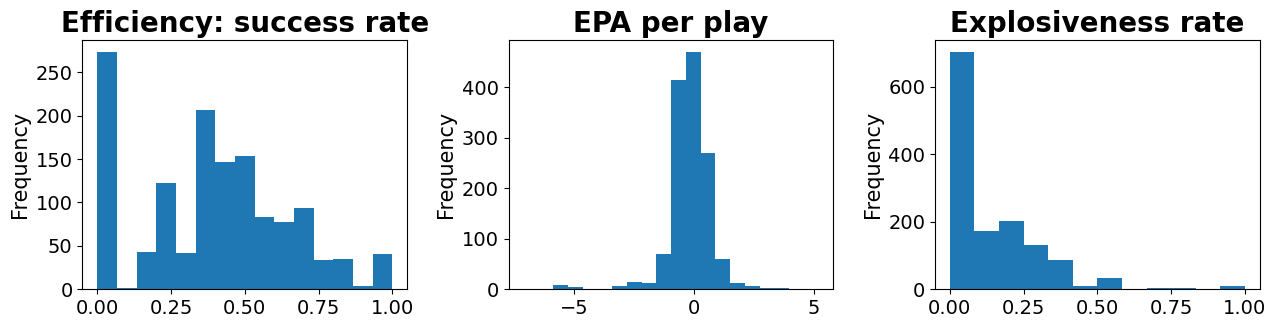


Finishing (drive-level counts):
reached opp 40: 705 drives | reached opp 20: 501 drives


In [17]:
# derive simple per-drive rates for viewing only (not saved, not a metric yet)
v = drives.copy()
v["success_rate"]   = v["success_plays"] / v["qualifying_plays"].replace(0, np.nan)
v["epa_per_play"]   = v["epa_sum"] / v["qualifying_plays"].replace(0, np.nan)
v["explosive_rate"] = v["explosive_plays"] / v["qualifying_plays"].replace(0, np.nan)

for c in ["success_rate","epa_per_play","explosive_rate"]:
    s = v[c].dropna()
    print(f"{c:15s} mean {s.mean():.3f} | median {s.median():.3f} | min {s.min():.3f} | max {s.max():.3f}")

fig, ax = plt.subplots(1, 3, figsize=(13,3.5))
v["success_rate"].dropna().plot(kind="hist", bins=15, ax=ax[0], title="Efficiency: success rate")
v["epa_per_play"].dropna().plot(kind="hist", bins=20, ax=ax[1], title="EPA per play")
v["explosive_rate"].dropna().plot(kind="hist", bins=12, ax=ax[2], title="Explosiveness rate")
plt.tight_layout(); plt.show()

print("\nFinishing (drive-level counts):")
print("reached opp 40:", int(v["reached_40"].sum()), "drives |",
      "reached opp 20:", int(v["reached_20"].sum()), "drives")

## 7. First look at relationships (eyeball only)\n\nA glance at whether the dimensions move with scoring. This is NOT the analysis, and we draw no conclusions. With one or two games these plots are noise; the point is that the code and the axes behave.

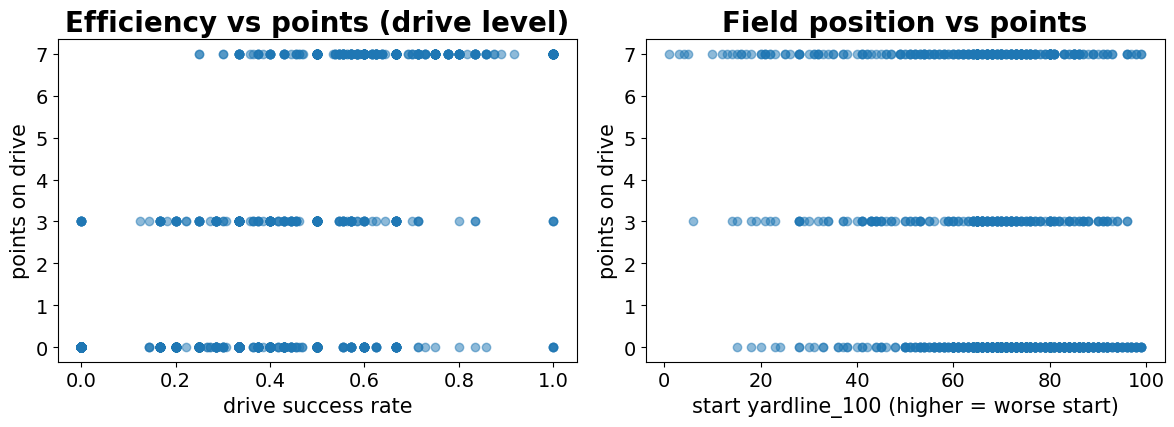

Reminder (Sec 19): these are associations within a tiny 2026 sample.
No claims. We are checking that the pipeline produces sane, plottable data.


In [18]:
v_ok = v.dropna(subset=["success_rate","epa_per_play"])

fig, ax = plt.subplots(1, 2, figsize=(12,4.5))

# efficiency vs points
ax[0].scatter(v_ok["success_rate"], v_ok["offensive_points"], alpha=0.5)
ax[0].set_xlabel("drive success rate"); ax[0].set_ylabel("points on drive")
ax[0].set_title("Efficiency vs points (drive level)")

# starting field position vs points
ax[1].scatter(v["start_yardline_100"], v["offensive_points"], alpha=0.5)
ax[1].set_xlabel("start yardline_100 (higher = worse start)")
ax[1].set_ylabel("points on drive")
ax[1].set_title("Field position vs points")
plt.tight_layout(); plt.show()

print("Reminder (Sec 19): these are associations within a tiny 2026 sample.")
print("No claims. We are checking that the pipeline produces sane, plottable data.")

## 8. Data-quality scan\n\nOne more automated pass for anything impossible, so we trust the table as the season grows.

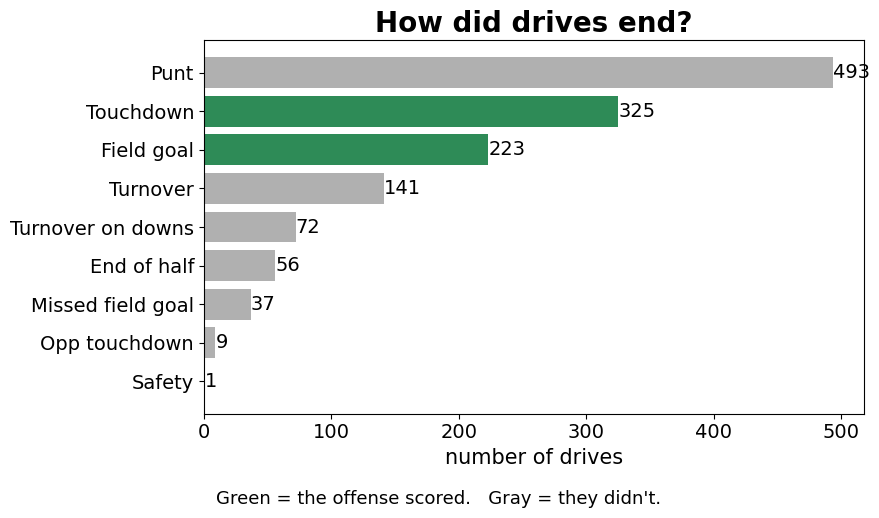

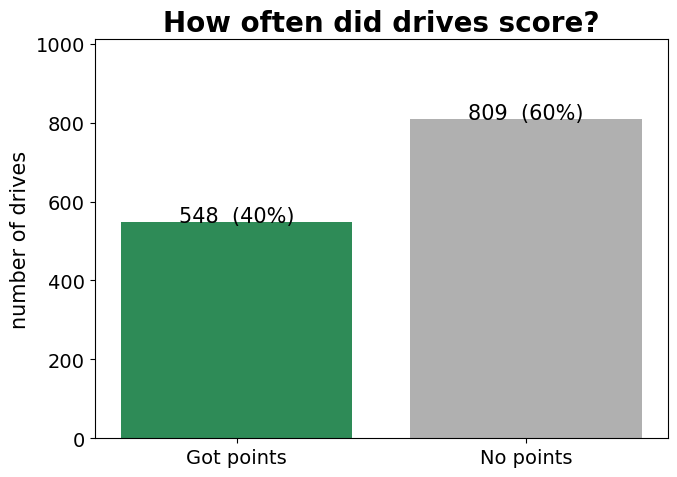

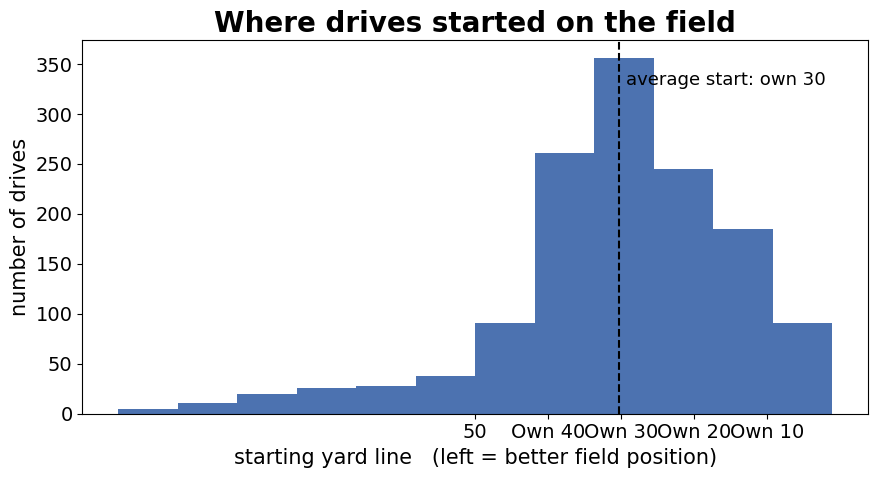

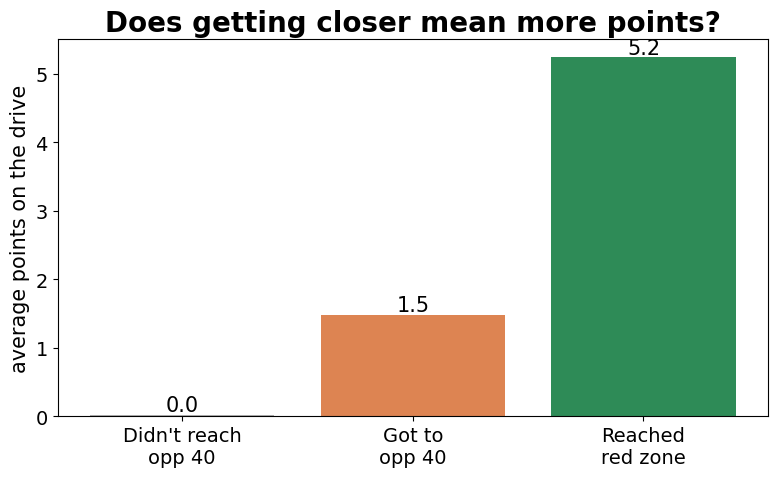

In [19]:
# ---- FAN-FRIENDLY CHARTS: plain English, big labels, green = points ----
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 14, "axes.titlesize": 20, "axes.titleweight": "bold",
    "axes.labelsize": 15, "figure.autolayout": True
})

SCORED = {"Touchdown", "Field goal"}
df = drives.copy()
df["scored"] = df["offensive_points"] > 0
GREEN, GRAY, ORANGE, BLUE = "#2e8b57", "#b0b0b0", "#dd8452", "#4c72b0"

# 1) How did drives end?  green = came away with points
vc = df["drive_result"].value_counts()
colors = [GREEN if r in SCORED else GRAY for r in vc.index]
plt.figure(figsize=(9,5))
bars = plt.barh(list(vc.index[::-1]), vc.values[::-1], color=colors[::-1])
for b, v in zip(bars, vc.values[::-1]):
    plt.text(v + 0.1, b.get_y() + b.get_height()/2, str(int(v)), va="center", fontsize=14)
plt.title("How did drives end?")
plt.xlabel("number of drives")
plt.figtext(0.5, -0.03, "Green = the offense scored.   Gray = they didn't.", ha="center", fontsize=13)
plt.show()

# 2) How often did they score?
n = len(df); scored = int(df["scored"].sum()); empty = n - scored
plt.figure(figsize=(7,5))
b = plt.bar(["Got points", "No points"], [scored, empty], color=[GREEN, GRAY])
for rect, v in zip(b, [scored, empty]):
    plt.text(rect.get_x() + rect.get_width()/2, v + 0.1, f"{v}  ({v/n*100:.0f}%)", ha="center", fontsize=15)
plt.title("How often did drives score?")
plt.ylabel("number of drives")
plt.ylim(0, max(scored, empty) * 1.25)
plt.show()

# 3) Where did drives start?
plt.figure(figsize=(9,5))
plt.hist(df["start_yardline_100"].dropna(), bins=12, color=BLUE)
avg = df["start_yardline_100"].mean()
plt.axvline(avg, color="black", ls="--")
plt.text(avg + 1, plt.ylim()[1]*0.88, f"average start: own {100-avg:.0f}", fontsize=13)

# relabel the axis in real yard lines instead of "yards to go"
ticks = [50, 60, 70, 80, 90]
labels = ["50", "Own 40", "Own 30", "Own 20", "Own 10"]
plt.xticks(ticks, labels)

plt.title("Where drives started on the field")
plt.xlabel("starting yard line   (left = better field position)")
plt.ylabel("number of drives")
plt.show()

# 4) Does getting closer mean more points?
def zone(row):
    if row["reached_20"] == 1: return "Reached\nred zone"
    if row["reached_40"] == 1: return "Got to\nopp 40"
    return "Didn't reach\nopp 40"
df["zone"] = df.apply(zone, axis=1)
order = ["Didn't reach\nopp 40", "Got to\nopp 40", "Reached\nred zone"]
means = df.groupby("zone")["offensive_points"].mean().reindex(order).fillna(0)
plt.figure(figsize=(8,5))
b = plt.bar(order, means.values, color=[GRAY, ORANGE, GREEN])
for rect, v in zip(b, means.values):
    plt.text(rect.get_x() + rect.get_width()/2, v + 0.05, f"{v:.1f}", ha="center", fontsize=15)
plt.title("Does getting closer mean more points?")
plt.ylabel("average points on the drive")
plt.show()

In [20]:
issues = []

if (drives["qualifying_plays"] <= 0).any():
    issues.append("drive(s) with zero qualifying plays slipped through the filter")
if not set(drives["offensive_points"].unique()).issubset({0,3,7}):
    issues.append("offensive_points has values outside {0,3,7}")
if ((drives["reached_20"]==1) & (drives["reached_40"]==0)).any():
    issues.append("reached_20 without reached_40")
if ((drives["td_drive"]==1) & (drives["fg_drive"]==1)).any():
    issues.append("a drive marked both TD and FG")
if (drives["success_plays"] > drives["qualifying_plays"]).any():
    issues.append("success_plays exceeds qualifying_plays")
if (drives["pass_plays"] + drives["rush_plays"] != drives["qualifying_plays"]).any():
    issues.append("pass+rush does not equal qualifying_plays")
if drives["posteam"].isna().any():
    issues.append("drive with no posteam")

print("issues found:", issues if issues else "none - table is internally consistent")

issues found: none - table is internally consistent


## What we learned / what's next

Fill this in each time you run it as the season grows:
- Do the drive-result proportions look like football?
- Is scoring rate landing in a believable range once samples build?
- Does starting field position center where it should?
- Do any dimensions look broken or degenerate?

**Phase 4 does not start until real games accumulate.** Only once teams approach the Sec 15 gate do we move to metric development and the first relationship analysis. Until then, re-run Phase 2 after each week's slate, then re-run this notebook and update the notes above.

We look before we calculate. That is the whole job right now.